# 06 — Explorer et améliorer le Random Forest

**Objectif :** tester si une recherche élargie améliore le classement des départs et si un seuil adapté augmente leur détection. Le notebook 05 reste la référence ; ses modèles et données ne sont pas modifiés.

Trois questions :
1. Quels paramètres, groupes de variables et encodages améliorent l’**average precision (AP)** ?
2. Le gain résiste-t-il à une **validation croisée imbriquée** ?
3. Quel compromis rappel/précision obtient-on en choisissant le seuil sur l’entraînement ?

Le test a déjà été consulté dans les analyses précédentes : ce travail est une exploration, pas une nouvelle validation indépendante. Les retraits de variables sont des hypothèses issues de l’analyse précédente, pas des découvertes indépendantes.

**Annexe archivée** : hors parcours de présentation. Les sorties exécutées historiques sont conservées ; leurs anciens chemins imprimés ne sont pas réécrits. Les réexécutions utilisent les chemins actuels du module associé.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'src/modeling.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Racine du projet introuvable.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from hashlib import sha256
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from src.modeling import load_model_data, make_split, verify_reference_split, MODEL_DIR
from src.forest_improvement import (OUT, candidates, export, nested_experiment,
    final_training, evaluate_final, plot_results, write_summary, save_metadata)
OUT.mkdir(parents=True, exist_ok=True)
protected = list((ROOT / 'data').rglob('*.xlsx')) + list(MODEL_DIR.glob('*'))
fingerprints = {str(p.relative_to(ROOT)): sha256(p.read_bytes()).hexdigest()
                for p in protected if p.is_file()}
print('Sorties isolées dans', OUT)

Sorties isolées dans /Users/alexandrelouguet/Desktop/Capgemini Invent/capgemini-invent-ozone/outputs/06_random_forest_improvement


## 1. Réutiliser les données et les partitions

La cible est `Attrition=Yes → départ=1`. Même source baseline, mêmes 1 518 lignes, mêmes 30 variables et mêmes cinq plis que 04/05. Toutes les décisions de sélection utilisent uniquement les 1 214 lignes d’entraînement. Le test de 304 lignes reste à l’écart jusqu’à la section 6.

Aucune imputation ni correction arbitraire. Les scores hors dictionnaire et incohérences d’ancienneté conservés dans le projet restent visibles dans ses audits.

In [2]:
X, y, source_rows, _, quantitative = load_model_data()
X_train, X_test, y_train, y_test, folds, split_rows = make_split(X, y, source_rows)
verify_reference_split(split_rows)
pd.testing.assert_frame_equal(pd.read_csv(MODEL_DIR / '04_indices_split_plis.csv'),
                              pd.read_csv(MODEL_DIR / '05_indices_split_plis.csv'))
meta05 = json.loads((MODEL_DIR / '05_metadonnees.json').read_text())
assert meta05['sha256_source'] == fingerprints[meta05['fichier']]
assert set(X_train.index).isdisjoint(X_test.index)
reference = joblib.load(MODEL_DIR / '05_RandomForest.joblib')
logistic = joblib.load(MODEL_DIR / '04_Logistique.joblib')
dummy = joblib.load(MODEL_DIR / '05_Baseline.joblib')
assert reference.classes_.tolist() == [0, 1]
display(export(pd.DataFrame({'partie': ['entraînement', 'test'],
    'n': [len(y_train), len(y_test)], 'départs': [int(y_train.sum()), int(y_test.sum())]}), 'split_summary'))
print('Référence RF 05 :', meta05['parametres']['RandomForest'])

,partie,n,départs
0,entraînement,1214,198
1,test,304,50


Référence RF 05 : {'modele__class_weight': None, 'modele__max_depth': None, 'modele__min_samples_leaf': 2}


## 2. Hypothèses et budget fixés avant l’évaluation du test

**20 configurations**, dont 8 contrôles à paramètres historiques (4 sous-ensembles × 2 encodages des scores), puis 12 configurations tirées avec `random_state=42` :

- toutes les variables ; sans rémunération ; sans profil ; sans ces deux groupes ;
- scores numériques existants ou one-hot (sans ordre supposé, mais davantage de colonnes) ;
- 200 ou 600 arbres, profondeur `None/8/16`, feuilles `1/2/4/8`, `max_features=sqrt/0.5/1.0` ;
- poids `None/balanced/balanced_subsample` et bootstrap complet ou à 80 %.

Le tirage n’explore pas toutes les combinaisons : c’est un budget limité et reproductible. L’AP de validation choisit la configuration. Aucun retrait supplémentaire ne sera décidé après lecture du test. Les comparaisons par sous-ensemble sont exploratoires : les configurations aléatoires ne forment pas un plan factoriel équilibré.

In [3]:
configurations = candidates(reference)
assert len(configurations) == 20
assert configurations[0]['subset'] == 'Toutes' and configurations[0]['score_encoding'] == 'numeric'
display(export(pd.DataFrame(configurations), 'candidate_configurations'))

,candidate,subset,score_encoding,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,max_samples
0,0,Toutes,numeric,200,NaN,2,sqrt,None,NaN
1,1,Toutes,onehot,200,NaN,2,sqrt,None,NaN
2,2,Sans remuneration,numeric,200,NaN,2,sqrt,None,NaN
3,3,Sans remuneration,onehot,200,NaN,2,sqrt,None,NaN
4,4,Sans profil,numeric,200,NaN,2,sqrt,None,NaN
5,5,Sans profil,onehot,200,NaN,2,sqrt,None,NaN
6,6,Sans remuneration ni profil,numeric,200,NaN,2,sqrt,None,NaN
7,7,Sans remuneration ni profil,onehot,200,NaN,2,sqrt,None,NaN
8,8,Sans profil,onehot,200,16.0,4,sqrt,balanced_subsample,0.8
9,9,Toutes,onehot,600,16.0,2,sqrt,None,0.8


## 3. Validation imbriquée : évaluer la procédure de sélection

Pour chacun des **cinq plis externes existants** :

1. Rechercher la meilleure configuration sur trois plis internes de l’entraînement externe.
2. Choisir un seuil maximisant **F2** à partir des prédictions internes hors pli du candidat retenu.
3. Réajuster uniquement sur l’entraînement externe et évaluer sur sa validation externe.

La référence bénéficie elle aussi d’un seuil F2 choisi dans les mêmes plis internes. Cela distingue le bénéfice du réglage du modèle de celui du seuil. F2 privilégie le rappel ; ce choix exploratoire ne représente pas encore un coût métier validé.

L’encodage, le sous-ensemble de variables et les poids sont ajustés dans chaque fit. Les modèles historiques servent de **gabarits clonés**, jamais à prédire leur propre entraînement pour choisir le seuil.

In [4]:
nested_detail, nested_pooled, intervals = nested_experiment(
    reference, configurations, X_train, y_train, folds)
display(nested_detail)
display(nested_detail.groupby(['model', 'policy'])[
    ['average_precision', 'roc_auc', 'precision', 'recall', 'f2']].agg(['mean', 'std']))
display(nested_pooled)
display(intervals)
print('IC bootstrap conditionnels aux prédictions externes ; pas des tests sur 5 plis indépendants.')

Externe 1/5 — configuration 1/20 : AP 0.579


Externe 1/5 — configuration 2/20 : AP 0.578


Externe 1/5 — configuration 3/20 : AP 0.566


Externe 1/5 — configuration 4/20 : AP 0.559


Externe 1/5 — configuration 5/20 : AP 0.582


Externe 1/5 — configuration 6/20 : AP 0.559


... (100 outputs left out)

average_precision             roc_auc            \
                                  mean       std      mean       std   
model     policy                                                       
Optimise  0.5                 0.552773  0.134104  0.798616  0.081064   
          F2_interne          0.552773  0.134104  0.798616  0.081064   
Reference 0.5                 0.558710  0.112233  0.799533  0.068555   
          F2_interne          0.558710  0.112233  0.799533  0.068555   

                     precision              recall                  f2  \
                          mean       std      mean       std      mean   
model     policy                                                         
Optimise  0.5         0.757540  0.217732  0.176923  0.040418  0.207963   
          F2_interne  0.310154  0.036325  0.787436  0.107177  0.601236   
Reference 0.5         0.781984  0.227904  0.166667  0.045402  0.197697   
          F2_interne  0.310908  0.059889  0.746282  0.157600  0.578275   

                                
                           std  
model     policy                
Optimise  0.5         0.045937  
          F2_interne  0.072876  
Reference 0.5         0.053927  
          F2_interne  0.099457

,model,policy,roc_auc,average_precision,precision,recall,f2,threshold,tn,fp,fn,tp,flagged_fraction
0,Reference,0.5,0.798773,0.541263,0.767442,0.166667,0.197605,0.5,1006,10,165,33,0.035420
1,Reference,F2_interne,0.798773,0.541263,0.307054,0.747475,0.580848,NaN,682,334,50,148,0.397035
2,Optimise,0.5,0.794254,0.522951,0.714286,0.176768,0.208086,0.5,1002,14,163,35,0.040362
3,Optimise,F2_interne,0.794254,0.522951,0.310139,0.787879,0.602317,NaN,669,347,42,156,0.414333


,metric,bootstrap_low,bootstrap_high
0,delta_ap,-0.053154,0.014197
1,delta_auc,-0.020408,0.012425


IC bootstrap conditionnels aux prédictions externes ; pas des tests sur 5 plis indépendants.


## 4. Lire les pistes d’amélioration sur l’entraînement

Les paramètres gagnants peuvent varier selon les plis : une forte instabilité réduit la confiance dans une configuration précise. La différence d’AP de chaque pli est conservée ; il ne faut pas choisir un modèle sur un seul pli favorable.

Les sorties agrégées OOF mélangent des modèles de plis différents. Elles complètent les résultats par pli, sans les remplacer. La référence historique et les hypothèses de groupes avaient déjà été exposées aux données : l’imbrication contrôle cette nouvelle recherche, sans effacer ce contexte.

In [5]:
selection_by_fold = pd.read_csv(OUT / 'nested_selected_configurations.csv')
display(selection_by_fold)
paired = nested_detail.query("policy == '0.5'").pivot(
    index='outer_fold', columns='model', values='average_precision')
paired['delta_AP'] = paired['Optimise'] - paired['Reference']
display(export(paired.reset_index(), 'nested_paired_ap'))

,candidate,subset,score_encoding,n_estimators,min_samples_leaf,max_samples,max_features,max_depth,class_weight,outer_fold
0,18,Sans profil,numeric,600,1,0.8,1.0,NaN,NaN,0
1,2,Sans remuneration,numeric,200,2,NaN,sqrt,NaN,NaN,1
2,0,Toutes,numeric,200,2,NaN,sqrt,NaN,NaN,2
3,2,Sans remuneration,numeric,200,2,NaN,sqrt,NaN,NaN,3
4,2,Sans remuneration,numeric,200,2,NaN,sqrt,NaN,NaN,4


model,outer_fold,Optimise,Reference,delta_AP
0,0,0.385772,0.456626,-0.070854
1,1,0.442287,0.432911,0.009376
2,2,0.693571,0.693571,0.000000
3,3,0.584556,0.576721,0.007835
4,4,0.657679,0.633724,0.023955


## 5. Configuration et seuil finaux : entraînement uniquement

Même liste de candidats, cette fois évaluée sur les cinq plis de tout l’entraînement. On choisit la meilleure AP moyenne, puis un seuil F2 à partir de ses prédictions hors pli. Ces scores servent à la sélection et sont donc optimistes ; la section 3 est la meilleure évaluation disponible de cette nouvelle procédure.

Abaisser le seuil change les décisions, **pas la ROC-AUC ni l’AP**. Une hausse de rappel peut augmenter fortement le nombre de faux positifs et de salariés signalés. Les probabilités pondérées ne sont pas présumées calibrées.

In [6]:
improved_model, selected, training_search = final_training(
    reference, configurations, X_train, y_train, folds)
display(training_search)
print(json.dumps(selected, ensure_ascii=False, indent=2))
restored = joblib.load(OUT / '06_RandomForest.joblib')
np.testing.assert_allclose(
    restored.predict_proba(X_train[selected['selected_columns']].iloc[:8]),
    improved_model.predict_proba(X_train[selected['selected_columns']].iloc[:8]))

Selection finale entrainement — configuration 1/20 : AP 0.559


Selection finale entrainement — configuration 2/20 : AP 0.556


Selection finale entrainement — configuration 3/20 : AP 0.574


Selection finale entrainement — configuration 4/20 : AP 0.548


Selection finale entrainement — configuration 5/20 : AP 0.574


Selection finale entrainement — configuration 6/20 : AP 0.541


... (12 outputs left out)

Selection finale entrainement — configuration 19/20 : AP 0.553


Selection finale entrainement — configuration 20/20 : AP 0.528


,candidate,subset,score_encoding,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,max_samples,mean_ap,sd_ap,mean_auc,pooled_oof_ap
2,2,Sans remuneration,numeric,200,NaN,2,sqrt,None,NaN,0.574084,0.116468,0.816304,0.554875
4,4,Sans profil,numeric,200,NaN,2,sqrt,None,NaN,0.573769,0.109335,0.808775,0.548086
9,9,Toutes,onehot,600,16.0,2,sqrt,None,0.8,0.563075,0.116725,0.807578,0.540129
16,16,Sans profil,numeric,200,8.0,2,sqrt,None,0.8,0.558962,0.123726,0.801241,0.532102
0,0,Toutes,numeric,200,NaN,2,sqrt,None,NaN,0.558710,0.112233,0.799533,0.541263
1,1,Toutes,onehot,200,NaN,2,sqrt,None,NaN,0.556181,0.112208,0.803600,0.537861
18,18,Sans profil,numeric,600,NaN,1,1.0,None,0.8,0.552851,0.106726,0.794596,0.530330
3,3,Sans remuneration,onehot,200,NaN,2,sqrt,None,NaN,0.548210,0.129354,0.796050,0.523782
17,17,Sans profil,onehot,200,NaN,2,sqrt,balanced,0.8,0.544804,0.124720,0.799879,0.526962
15,15,Sans remuneration,numeric,600,16.0,8,0.5,balanced,0.8,0.543872,0.134425,0.790268,0.518668


{
  "candidate": 2,
  "subset": "Sans remuneration",
  "score_encoding": "numeric",
  "n_estimators": 200,
  "max_depth": null,
  "min_samples_leaf": 2,
  "max_features": "sqrt",
  "class_weight": null,
  "max_samples": null,
  "selected_columns": [
    "Age",
    "BusinessTravel",
    "Department",
    "DistanceFromHome",
    "Education",
    "EducationField",
    "EnvironmentSatisfaction",
    "Gender",
    "JobInvolvement",
    "JobLevel",
    "JobRole",
    "JobSatisfaction",
    "MaritalStatus",
    "NumCompaniesWorked",
    "OverTime",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "WorkLifeBalance",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
  ],
  "f2_threshold": 0.14662202380952377,
  "reference_f2_threshold": 0.14508333333333334,
  "selection": "mean inner-fold average precision; threshold maximizes OOF F2"
}


## 6. Comparaison finale sur le test historique

La configuration et les deux seuils F2 sont maintenant figés. Une seule prédiction par modèle sur le test : RF 05, RF 06, logistique 04 et dummy. Pour chaque forêt, on compare le seuil 0,5 au seuil choisi sur l’entraînement.

**Ne pas relancer une recherche après cette lecture pour optimiser le test.** Un meilleur résultat sur ce test ne suffit pas à démontrer une amélioration générale.

,model,policy,roc_auc,average_precision,precision,recall,f2,threshold,tn,fp,fn,tp,flagged_fraction
0,RF 05,0.5,0.818819,0.506820,0.857143,0.24,0.280374,0.500000,252,2,38,12,0.046053
1,RF 05,F2_entrainement,0.818819,0.506820,0.335938,0.86,0.655488,0.145083,169,85,7,43,0.421053
2,RF 06,0.5,0.820472,0.532336,0.750000,0.24,0.277778,0.500000,250,4,38,12,0.052632
3,RF 06,F2_entrainement,0.820472,0.532336,0.315789,0.84,0.630631,0.146622,163,91,8,42,0.437500
4,Logistique 04,0.5,0.868661,0.685237,0.800000,0.32,0.363636,0.500000,250,4,34,16,0.065789
5,Dummy,0.5,0.500000,0.164474,0.000000,0.00,0.000000,0.500000,254,0,50,0,0.000000


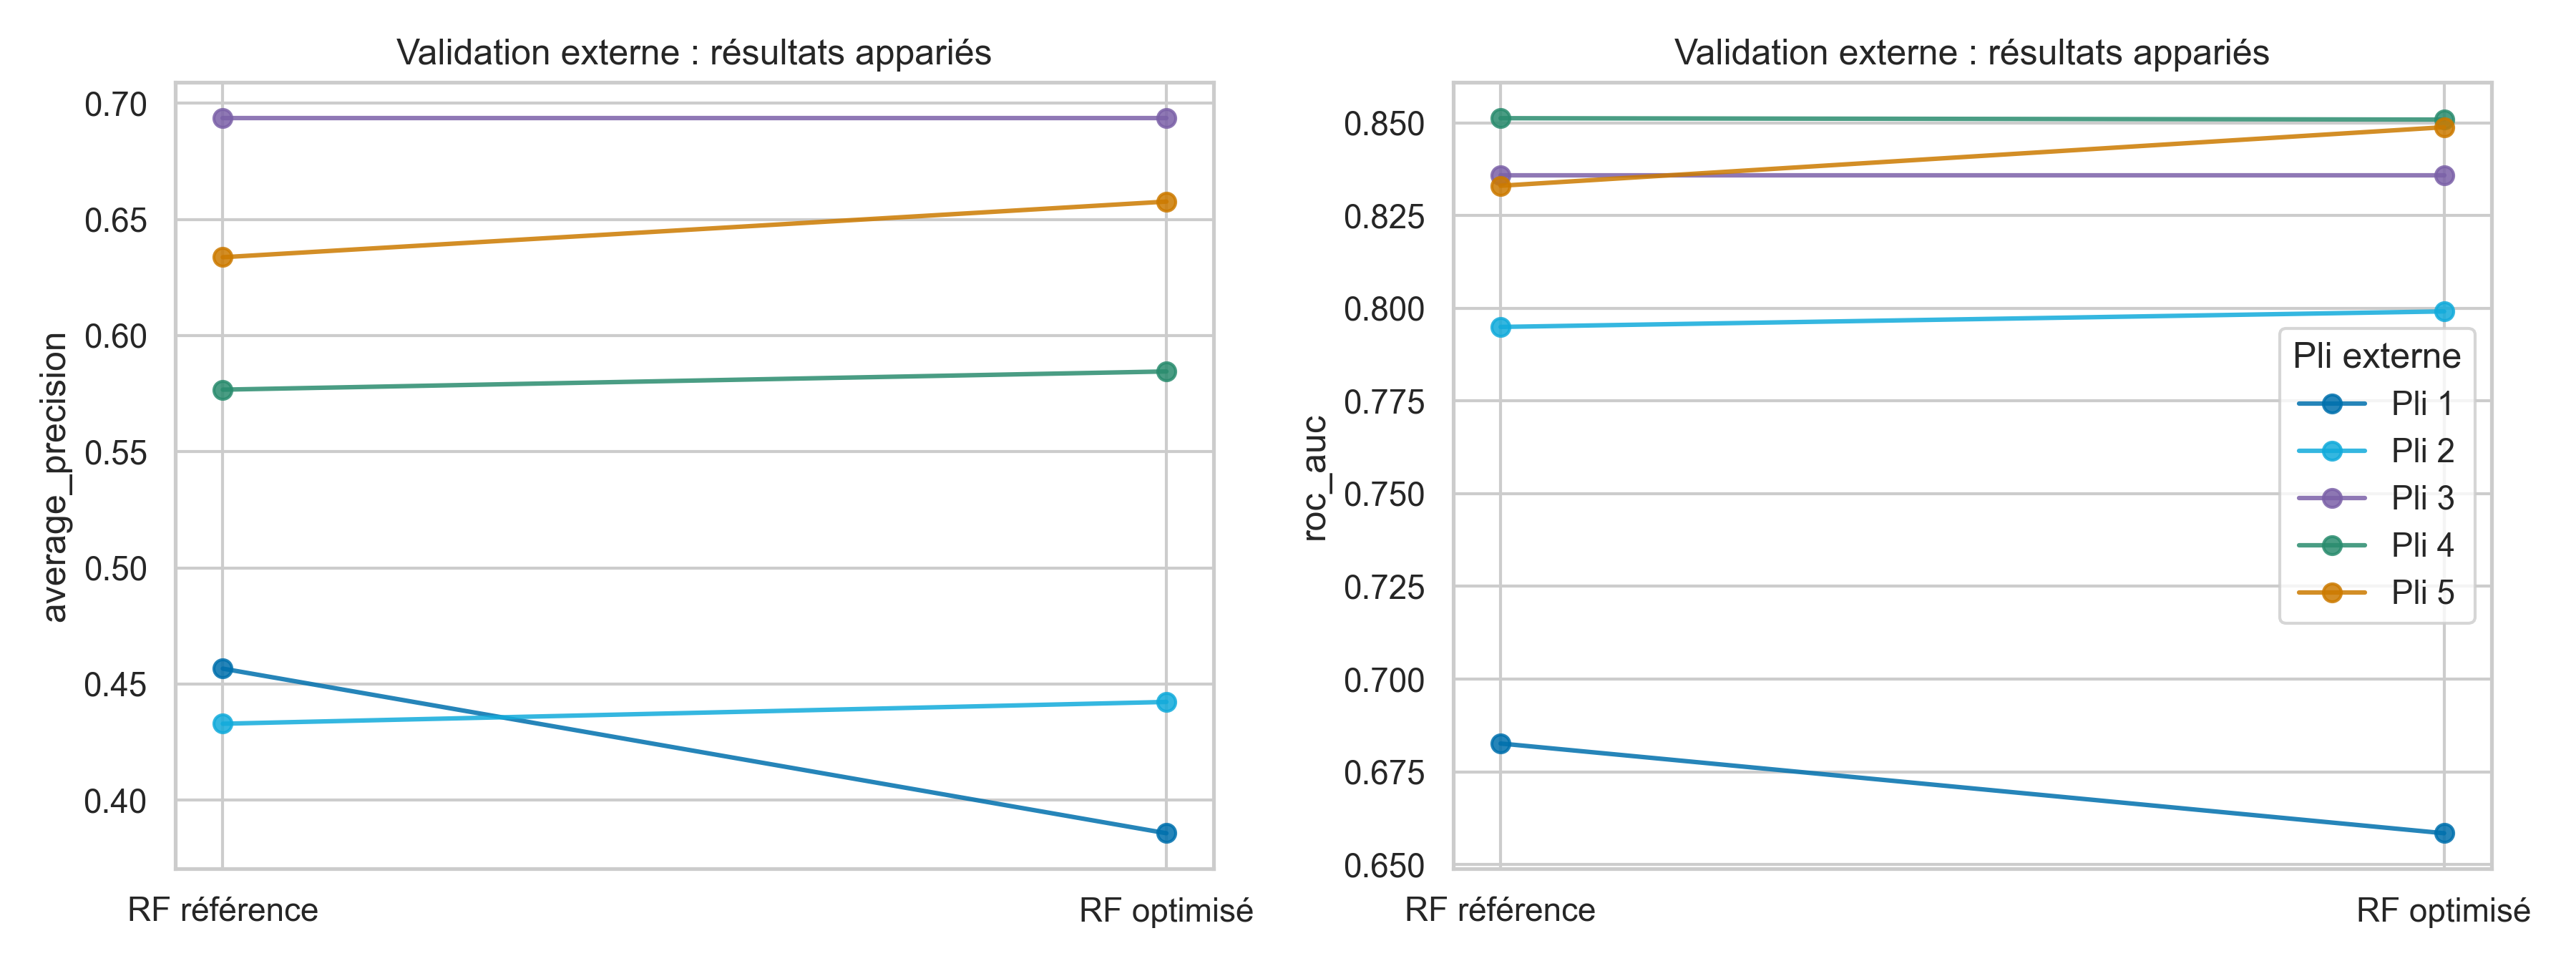

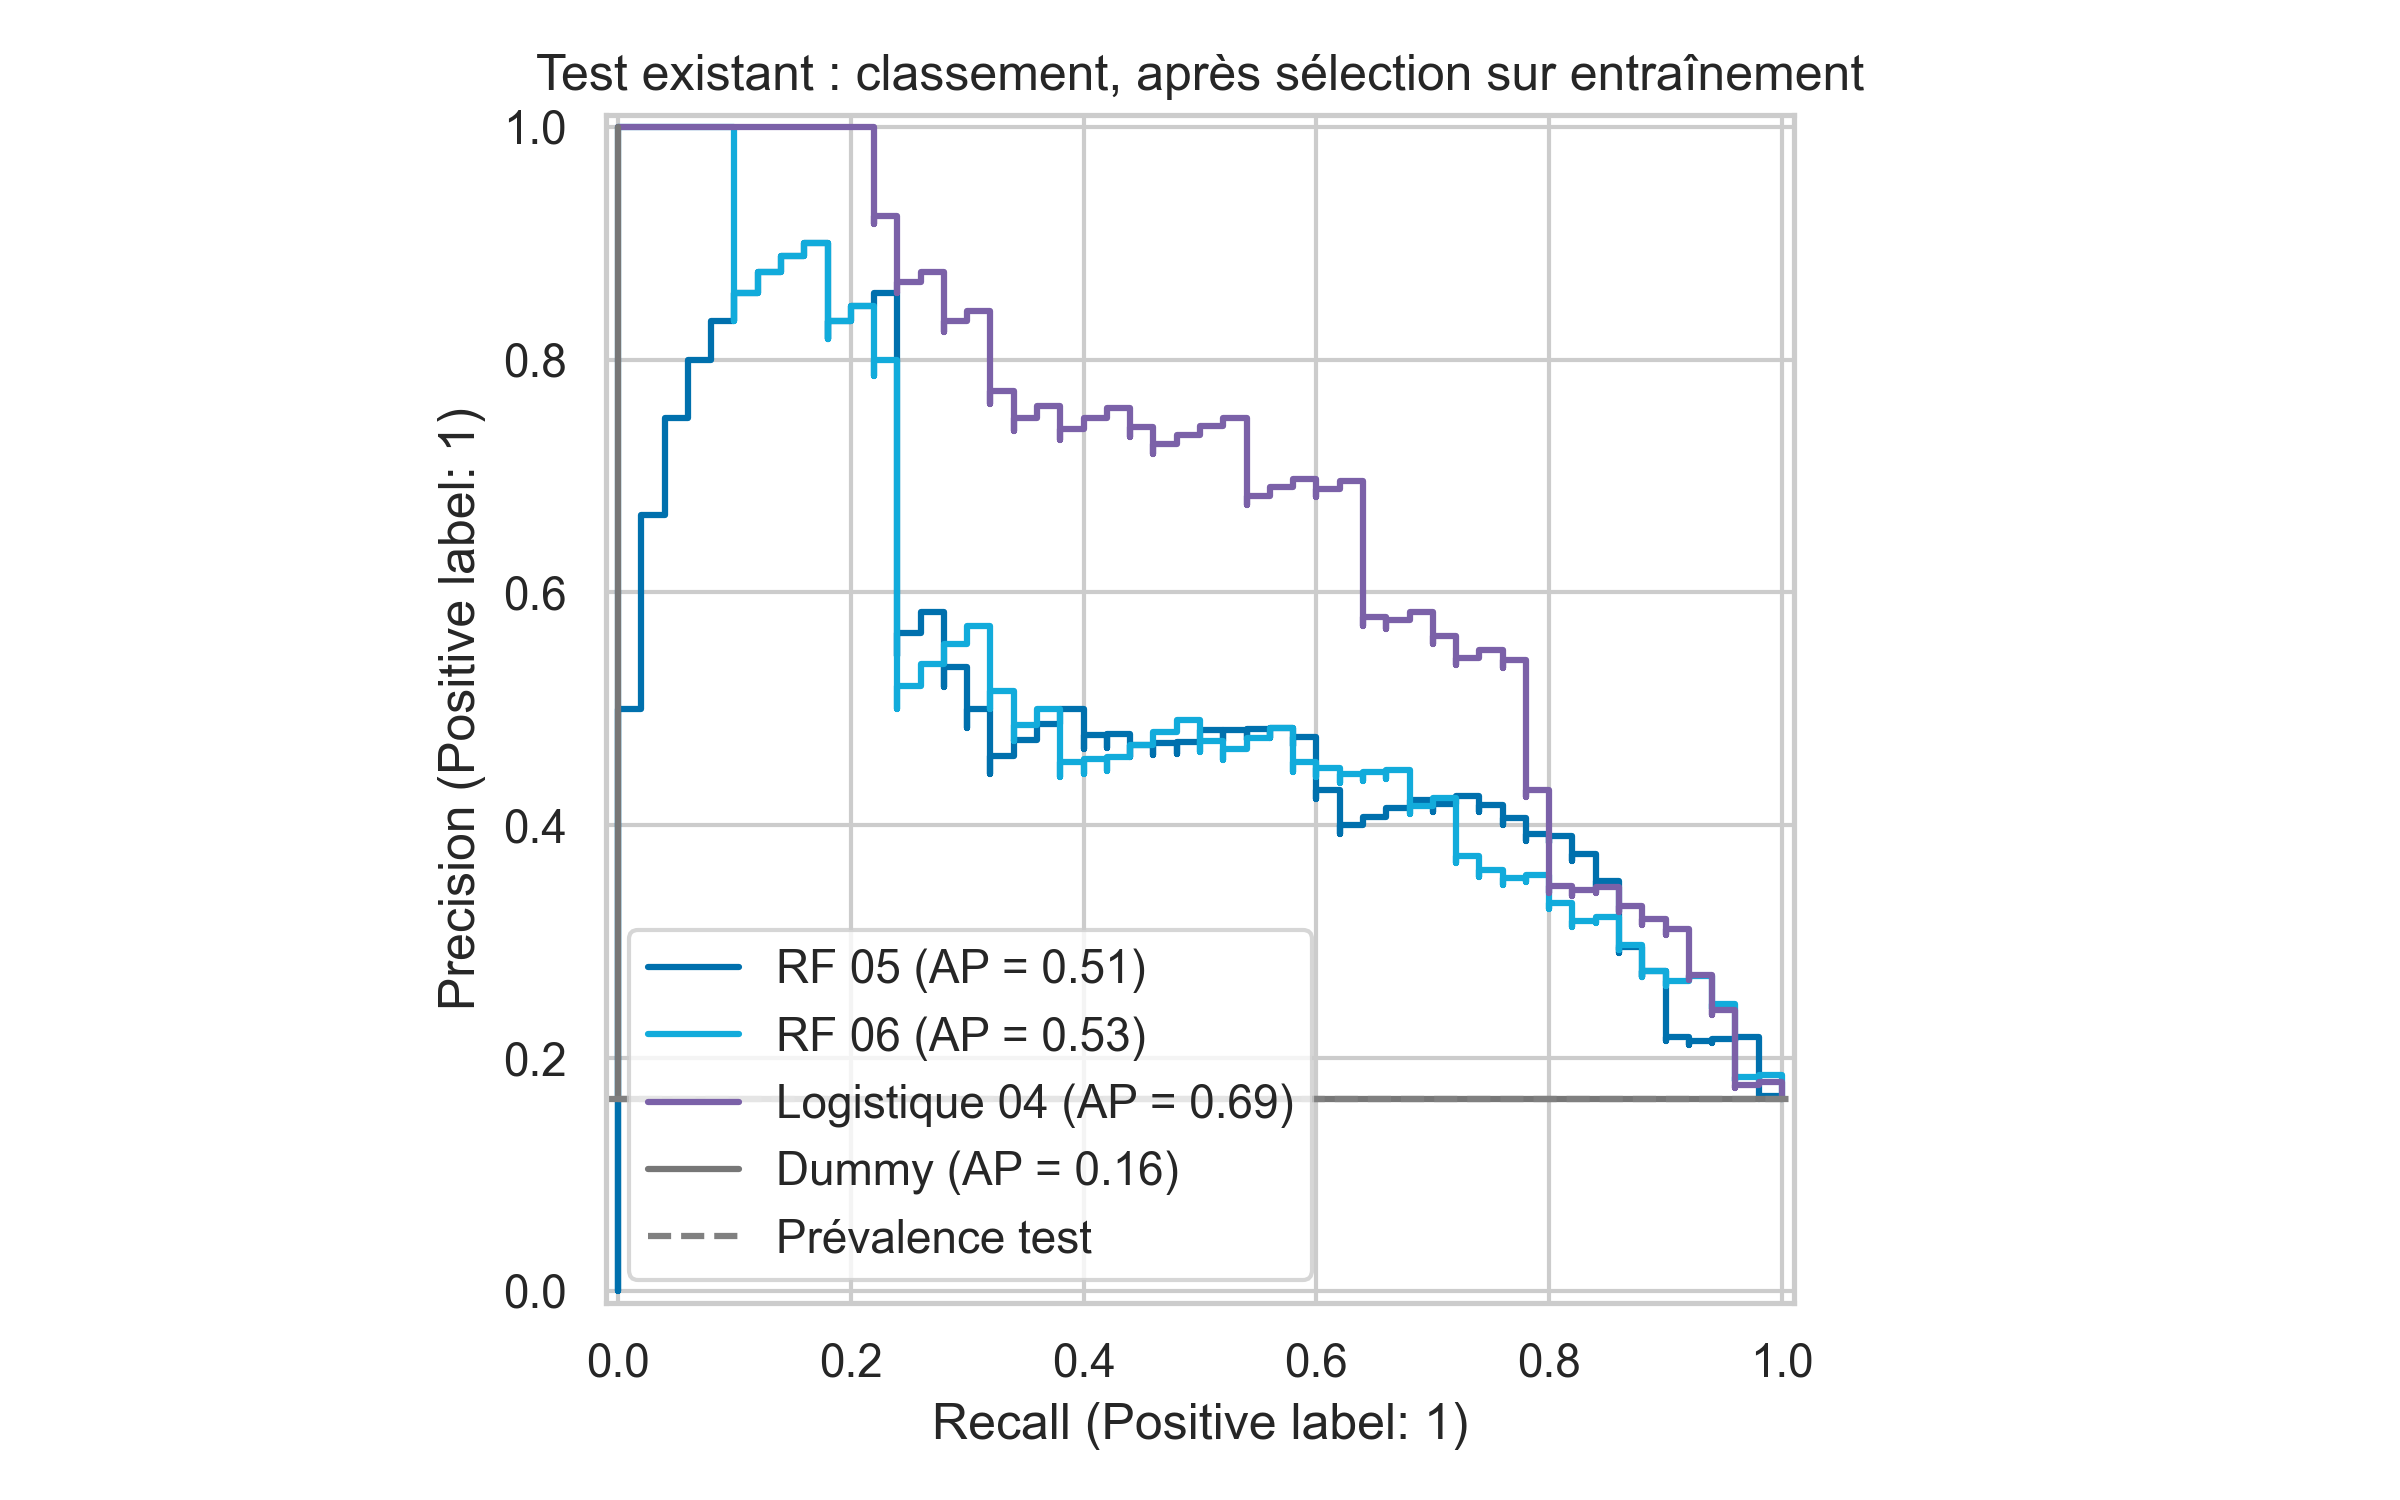

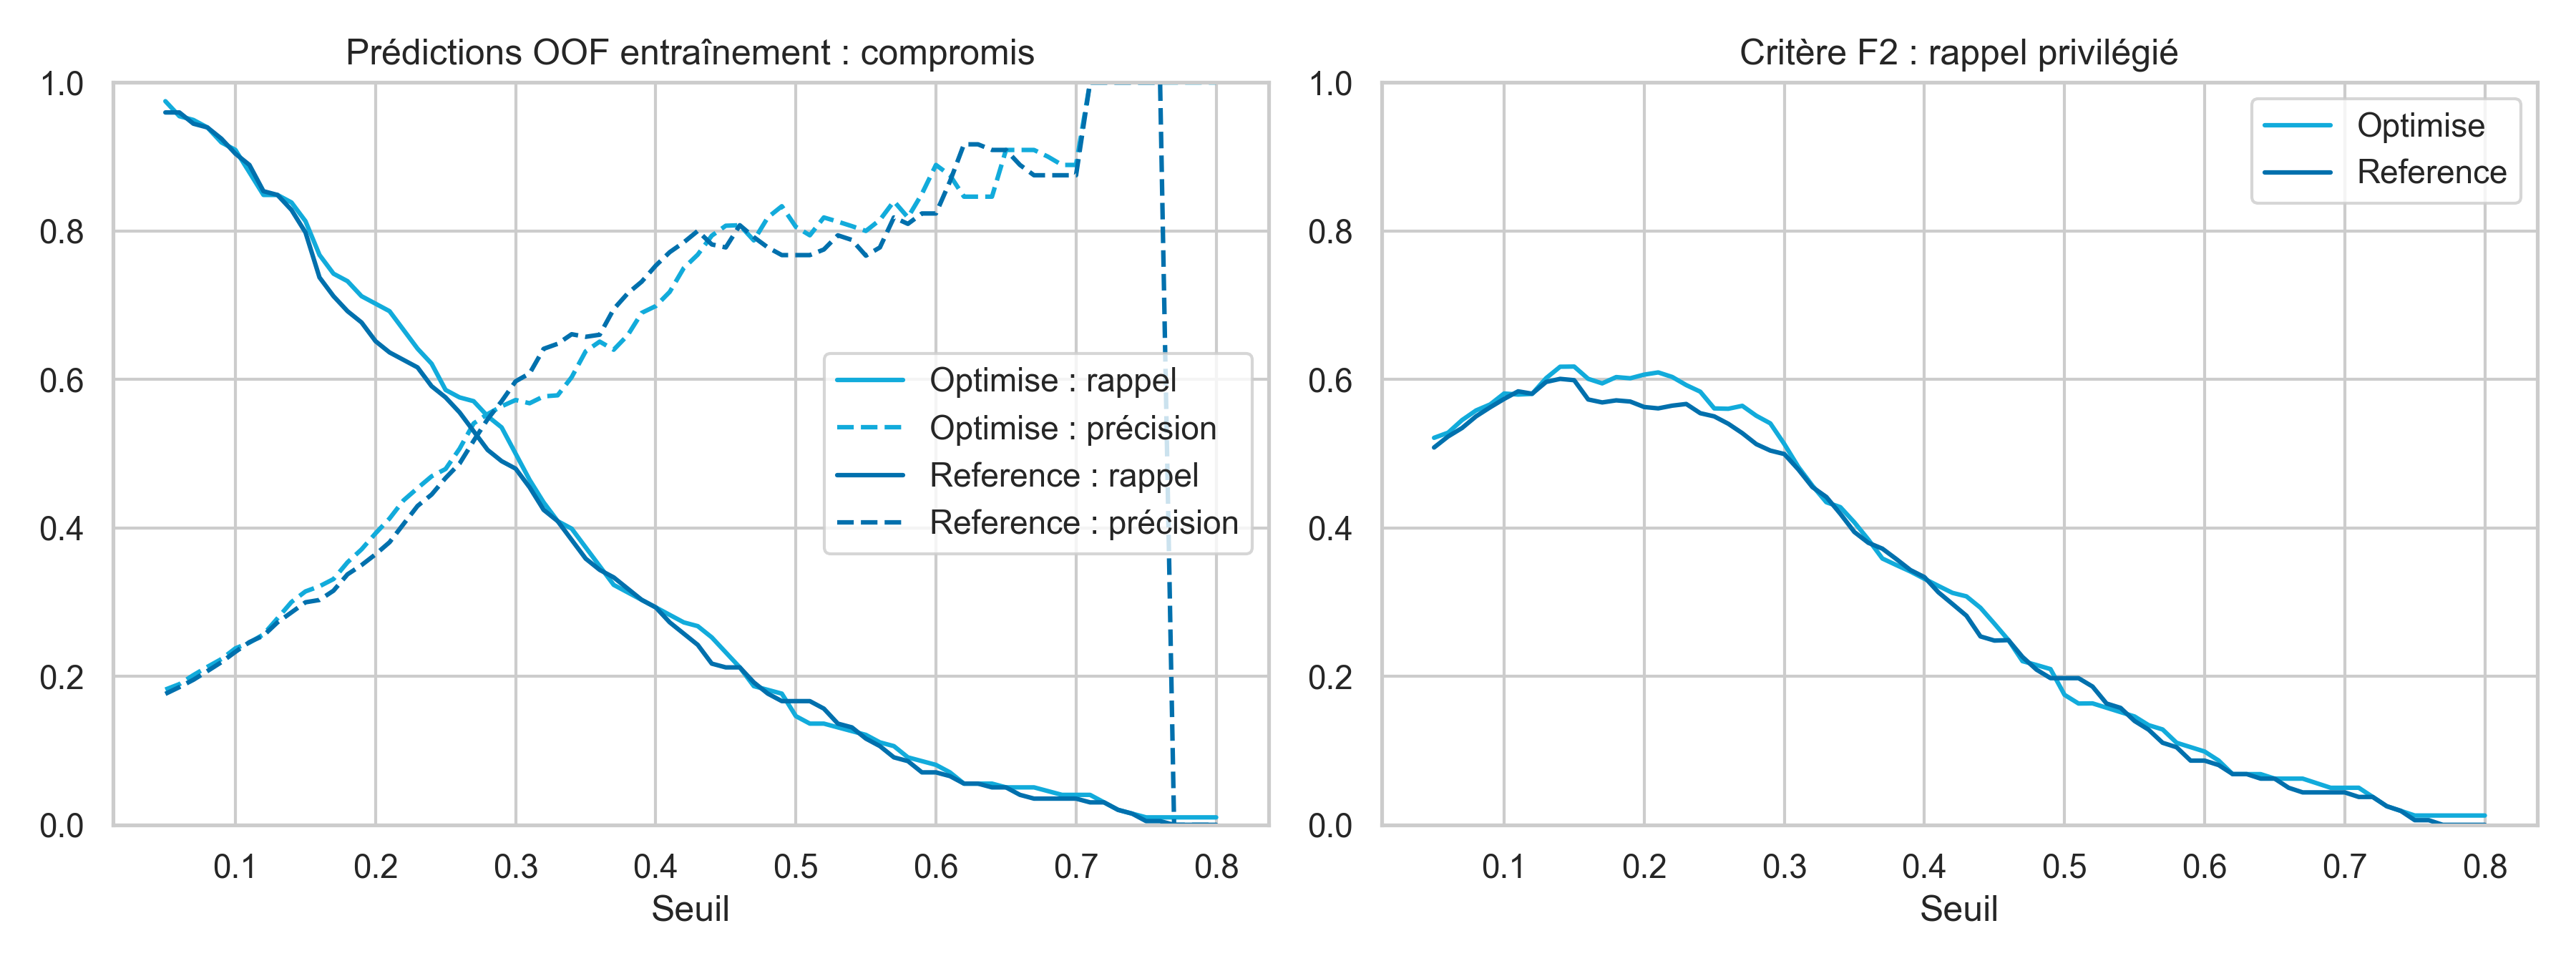

In [2]:
test_comparison, test_predictions = evaluate_final(
    improved_model, selected, reference, logistic, dummy, X_test, y_test)
display(test_comparison)
plot_results(nested_detail, test_comparison, test_predictions, y_test)

## 7. Conclusion à partir des résultats calculés

Le rapport ci-dessous est généré à partir des sorties réelles. Il distingue gain de classement et hausse du rappel par changement de seuil. Aucune amélioration n’est promise : une égalité, une dégradation ou des résultats instables doivent être conservés et expliqués.

Avant tout usage RH, fixer une capacité d’accompagnement et un objectif de précision/rappel, puis valider sur une nouvelle cohorte temporelle. Les associations ne démontrent pas les causes des départs ni l’effet d’une intervention.

In [3]:
write_summary(nested_detail, nested_pooled, intervals, test_comparison, selected)
save_metadata(selected, fingerprints, configurations)
required = ['06_RandomForest.joblib', '06_metadata.json', '06_exploration_report.md',
    'nested_fold_scores.csv', 'nested_pooled_scores.csv', 'training_search.csv',
    'test_comparison.csv', 'selected_configuration.json']
for name in required:
    assert (OUT / name).is_file() and (OUT / name).stat().st_size > 0, name
assert len(nested_detail) == 20
assert nested_detail.groupby(['model', 'policy']).outer_fold.nunique().eq(5).all()
print('Exports vérifiés ; sources et modèles 04/05 inchangés.')
display(Markdown((OUT / '06_exploration_report.md').read_text()))

Exports vérifiés ; sources et modèles 04/05 inchangés.


# 06 — Exploration pour améliorer le Random Forest

## Résultats observés

Validation externe : variation d’AP OOF agrégée de -0.018 ; amélioration sur 3/5 plis. Les scores agrégés mélangent des modèles ajustés dans des plis différents ; consulter aussi les scores appariés par pli.

| model | policy | average_precision | roc_auc | precision | recall | f2 | threshold | fp | tp | flagged_fraction |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference | 0.5 | 0.541 | 0.799 | 0.767 | 0.167 | 0.198 | 0.500 | 10 | 33 | 0.035 |
| Reference | F2_interne | 0.541 | 0.799 | 0.307 | 0.747 | 0.581 | variable par pli | 334 | 148 | 0.397 |
| Optimise | 0.5 | 0.523 | 0.794 | 0.714 | 0.177 | 0.208 | 0.500 | 14 | 35 | 0.040 |
| Optimise | F2_interne | 0.523 | 0.794 | 0.310 | 0.788 | 0.602 | variable par pli | 347 | 156 | 0.414 |

| metric | bootstrap_low | bootstrap_high |
|---|---|---|
| delta_ap | -0.053 | 0.014 |
| delta_auc | -0.020 | 0.012 |

Le gain de classement n’est pas confirmé : l’intervalle conditionnel de différence d’AP contient zéro.

Test historique : AP 0.507 → 0.532, ROC-AUC 0.819 → 0.820. Au seuil F2 choisi sur entraînement (0.147), rappel 84.0%, précision 31.6%, 42 départs détectés et 91 faux positifs.

| model | policy | average_precision | roc_auc | precision | recall | f2 | threshold | fp | tp | flagged_fraction |
|---|---|---|---|---|---|---|---|---|---|---|
| RF 05 | 0.5 | 0.507 | 0.819 | 0.857 | 0.240 | 0.280 | 0.500 | 2 | 12 | 0.046 |
| RF 05 | F2_entrainement | 0.507 | 0.819 | 0.336 | 0.860 | 0.655 | 0.145 | 85 | 43 | 0.421 |
| RF 06 | 0.5 | 0.532 | 0.820 | 0.750 | 0.240 | 0.278 | 0.500 | 4 | 12 | 0.053 |
| RF 06 | F2_entrainement | 0.532 | 0.820 | 0.316 | 0.840 | 0.631 | 0.147 | 91 | 42 | 0.438 |
| Logistique 04 | 0.5 | 0.685 | 0.869 | 0.800 | 0.320 | 0.364 | 0.500 | 4 | 16 | 0.066 |
| Dummy | 0.5 | 0.164 | 0.500 | 0.000 | 0.000 | 0.000 | 0.500 | 0 | 0 | 0.000 |

La référence bénéficie elle aussi du réglage du seuil : rappel 86.0%, précision 33.6%, F2 0.655, contre F2 0.631 pour le candidat. Le choix du seuil et le choix du modèle sont donc deux décisions distinctes. La logistique reste une référence concurrente à comparer sur les mêmes objectifs métier.

## Configuration choisie sur entraînement

```json
{
  "candidate": 2,
  "subset": "Sans remuneration",
  "score_encoding": "numeric",
  "n_estimators": 200,
  "max_depth": null,
  "min_samples_leaf": 2,
  "max_features": "sqrt",
  "class_weight": null,
  "max_samples": null,
  "selected_columns": [
    "Age",
    "BusinessTravel",
    "Department",
    "DistanceFromHome",
    "Education",
    "EducationField",
    "EnvironmentSatisfaction",
    "Gender",
    "JobInvolvement",
    "JobLevel",
    "JobRole",
    "JobSatisfaction",
    "MaritalStatus",
    "NumCompaniesWorked",
    "OverTime",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "WorkLifeBalance",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
  ],
  "f2_threshold": 0.14662202380952377,
  "reference_f2_threshold": 0.14508333333333334,
  "selection": "mean inner-fold average precision; threshold maximizes OOF F2"
}
```

## Interprétation et limites

La sélection optimise l’average precision, pas le score test. Le seuil maximise F2 sur des prédictions hors pli d’entraînement : le rappel reçoit davantage de poids que la précision. Ce choix est exploratoire, à remplacer par un objectif métier de capacité/coût ; il ne modifie ni l’AUC ni l’AP du modèle. Le réglage du seuil de la référence est également évalué pour distinguer l’effet du seuil de celui du modèle.

Cinq plis externes identiques aux expériences précédentes ; trois plis internes par pli externe pour les 20 configurations. La configuration et le seuil sont choisis sans les labels du pli externe. La sélection finale réutilise les cinq plis sur tout l’entraînement. Les recherches incluent des retraits de groupes et un encodage one-hot des scores pour éviter de supposer leur ordre. Pas de changement des valeurs sources, pas de SMOTE hors pipeline.

Les hypothèses de retrait et la référence viennent de travaux ayant déjà consulté ces données, parfois le test. La validation imbriquée contrôle la nouvelle recherche, sans effacer ce contexte exploratoire. Les IC bootstrap sur les prédictions externes sont conditionnels aux modèles et ne représentent pas toute la variabilité du réentraînement ; les plis ont des ensembles d’apprentissage qui se recouvrent. Aucun test de significativité fondé sur cinq plis supposés indépendants. Une différence faible ou un intervalle contenant zéro ne démontre pas une amélioration robuste.

20 configurations forment un budget limité, pas une recherche exhaustive. Une hausse sur le seul test ne suffit pas à choisir le modèle. Aucun essai additionnel n’est décidé après son évaluation. Le test existant sert de comparaison historique, pas de validation externe indépendante. Les scores hors dictionnaire et incohérences d’ancienneté restent présents. Les associations prédictives ne mesurent pas l’effet causal d’une politique RH.

## Suite proposée

Confronter le gain aux résultats externes par pli et aux intervalles. Valider un seuil avec la capacité d’accompagnement RH puis évaluer prospectivement sur une nouvelle cohorte temporelle. Conserver la logistique comme référence concurrente et ne pas remplacer le RF 05 sur la seule base du test.
